In [1]:
import numpy as np
import pandas as pd
import scipy
import torch
import time
import platform

from scipy.sparse import diags
from IPython.display import display

print("Environment initialized successfully!")

Environment initialized successfully!


In [2]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("No GPU detected. Enable GPU from Runtime settings.")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

Selected device: cuda


In [4]:
def generate_spd_matrix(n):

    diagonals = [
        -np.ones(n - 1),
         2 * np.ones(n),
        -np.ones(n - 1)
    ]

    A = diags(
        diagonals,
        offsets=[-1, 0, 1],
        format="csr"
    )

    return A

In [5]:
matrix_sizes = [1000, 5000, 10000, 20000, 50000]

matrix_info = []

for n in matrix_sizes:

    A = generate_spd_matrix(n)

    nnz = A.nnz
    total_elements = n * n
    sparsity = 1 - (nnz / total_elements)

    matrix_info.append({
        "Matrix_Size": n,
        "Non_Zero_Elements": nnz,
        "Sparsity_Percentage": sparsity * 100,
        "Data_Type": str(A.dtype)
    })

matrix_df = pd.DataFrame(matrix_info)

display(matrix_df)

,Matrix_Size,Non_Zero_Elements,Sparsity_Percentage,Data_Type
0,1000,2998,99.700200,float64
1,5000,14998,99.940008,float64
2,10000,29998,99.970002,float64
3,20000,59998,99.985000,float64
4,50000,149998,99.994000,float64


In [6]:
def generate_cg_problem(n):

    A = generate_spd_matrix(n)

    x_true = np.ones(n, dtype=np.float64)

    b = A @ x_true

    x0 = np.zeros(n, dtype=np.float64)

    return A, b, x0, x_true

In [7]:
n = 1000

A, b, x0, x_true = generate_cg_problem(n)

print("Matrix shape:", A.shape)
print("Non-zero elements:", A.nnz)
print("Right-hand-side shape:", b.shape)
print("Initial solution shape:", x0.shape)

print("\nFirst 10 values of b:", b[:10])
print("Last 10 values of b:", b[-10:])

print("\nKnown solution:", x_true[:5])

Matrix shape: (1000, 1000)
Non-zero elements: 2998
Right-hand-side shape: (1000,)
Initial solution shape: (1000,)

First 10 values of b: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Last 10 values of b: [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]

Known solution: [1. 1. 1. 1. 1.]


# CPU Becnchmark

In [8]:
from scipy.sparse.linalg import cg
import time

def benchmark_cpu_cg(n, rtol=1e-6, maxiter=100000):

    A, b, x0, x_true = generate_cg_problem(n)

    iterations = [0]

    def count_iteration(xk):
        iterations[0] += 1

    start = time.perf_counter()

    x, info = cg(
        A,
        b,
        x0=x0,
        rtol=rtol,
        atol=0,
        maxiter=maxiter,
        callback=count_iteration
    )

    execution_time = (time.perf_counter() - start) * 1000

    relative_residual = (
        np.linalg.norm(A @ x - b) / np.linalg.norm(b)
    )

    return {
        "Matrix_Size": n,
        "NNZ": A.nnz,
        "Hardware": "CPU",
        "Execution_Time_ms": execution_time,
        "Iterations": iterations[0],
        "Relative_Residual": relative_residual,
        "Converged": info == 0 and relative_residual <= rtol
    }

In [9]:
result = benchmark_cpu_cg(1000)

display(pd.DataFrame([result]))

,Matrix_Size,NNZ,Hardware,Execution_Time_ms,Iterations,Relative_Residual,Converged
0,1000,2998,CPU,43.10637,500,3.550271e-12,True


In [10]:
cpu_results = []

for n in matrix_sizes:

    print(f"Benchmarking matrix size: {n}")

    result = benchmark_cpu_cg(n)

    cpu_results.append(result)

    print(
        f"Time: {result['Execution_Time_ms']:.3f} ms | "
        f"Iterations: {result['Iterations']} | "
        f"Converged: {result['Converged']}"
    )

cpu_df = pd.DataFrame(cpu_results)

display(cpu_df)

Benchmarking matrix size: 1000
Time: 50.726 ms | Iterations: 500 | Converged: True
Benchmarking matrix size: 5000
Time: 333.074 ms | Iterations: 2500 | Converged: True
Benchmarking matrix size: 10000
Time: 1026.809 ms | Iterations: 5000 | Converged: True
Benchmarking matrix size: 20000
Time: 7540.121 ms | Iterations: 10000 | Converged: True
Benchmarking matrix size: 50000
Time: 17246.822 ms | Iterations: 25000 | Converged: True


,Matrix_Size,NNZ,Hardware,Execution_Time_ms,Iterations,Relative_Residual,Converged
0,1000,2998,CPU,50.726135,500,3.550271e-12,True
1,5000,14998,CPU,333.074298,2500,3.379695e-11,True
2,10000,29998,CPU,1026.809271,5000,1.737908e-10,True
3,20000,59998,CPU,7540.120597,10000,3.003544e-10,True
4,50000,149998,CPU,17246.822045,25000,1.512933e-09,True


In [11]:
cpu_df.to_csv(
    "week06_cpu_cg_results.csv",
    index=False
)

print("CPU benchmark dataset saved successfully!")

display(cpu_df)

CPU benchmark dataset saved successfully!


,Matrix_Size,NNZ,Hardware,Execution_Time_ms,Iterations,Relative_Residual,Converged
0,1000,2998,CPU,50.726135,500,3.550271e-12,True
1,5000,14998,CPU,333.074298,2500,3.379695e-11,True
2,10000,29998,CPU,1026.809271,5000,1.737908e-10,True
3,20000,59998,CPU,7540.120597,10000,3.003544e-10,True
4,50000,149998,CPU,17246.822045,25000,1.512933e-09,True


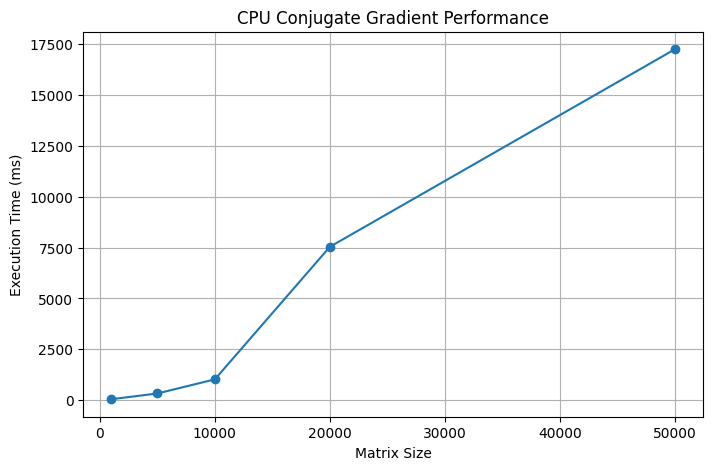

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    cpu_df["Matrix_Size"],
    cpu_df["Execution_Time_ms"],
    marker="o"
)

plt.xlabel("Matrix Size")
plt.ylabel("Execution Time (ms)")
plt.title("CPU Conjugate Gradient Performance")
plt.grid(True)

plt.show()

In [13]:
# Create a copy of the CPU benchmark results
ml_dataset = cpu_df.copy()

# Add matrix characteristics
ml_dataset["Sparsity_Percentage"] = [
    (1 - row["NNZ"] / (row["Matrix_Size"] ** 2)) * 100
    for _, row in ml_dataset.iterrows()
]

ml_dataset["Hardware_Code"] = 0  # 0 = CPU, 1 = GPU

# Reorder columns
ml_dataset = ml_dataset[
    [
        "Matrix_Size",
        "NNZ",
        "Sparsity_Percentage",
        "Hardware_Code",
        "Execution_Time_ms",
        "Iterations",
        "Relative_Residual",
        "Converged"
    ]
]

display(ml_dataset)

,Matrix_Size,NNZ,Sparsity_Percentage,Hardware_Code,Execution_Time_ms,Iterations,Relative_Residual,Converged
0,1000,2998,99.700200,0,50.726135,500,3.550271e-12,True
1,5000,14998,99.940008,0,333.074298,2500,3.379695e-11,True
2,10000,29998,99.970002,0,1026.809271,5000,1.737908e-10,True
3,20000,59998,99.985000,0,7540.120597,10000,3.003544e-10,True
4,50000,149998,99.994000,0,17246.822045,25000,1.512933e-09,True


In [14]:
ml_dataset.to_csv(
    "week06_ml_dataset.csv",
    index=False
)

print("ML dataset prepared successfully!")
print("Dataset shape:", ml_dataset.shape)

ML dataset prepared successfully!
Dataset shape: (5, 8)


# GPU Benchmark

In [15]:
import torch
from numba import cuda

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Numba CUDA available:", cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

device = torch.device("cuda")

a = torch.randn(1000, 1000, device=device)
b = torch.randn(1000, 1000, device=device)

c = torch.matmul(a, b)

torch.cuda.synchronize()

print("Matrix multiplication completed!")
print("Device:", c.device)
print("Output shape:", c.shape)

PyTorch: 2.14.1+cu130
CUDA available: True
Numba CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB
Matrix multiplication completed!
Device: cuda:0
Output shape: torch.Size([1000, 1000])


In [16]:
import numpy as np
from scipy.sparse import diags

N=1000

main_diags=2.0*np.ones(N)
off_diags=-1.0*np.ones(N-1)

A=diags([
    off_diags,
    main_diags,
    off_diags
],
        offsets=[-1,0,1],
        format='csr'
)

print("Matrix shape:",A.shape)
print("Number of non-zero elements:", A.nnz)
print("Storage format:", A.format)
print("Density:", A.nnz / (N * N))

Matrix shape: (1000, 1000)
Number of non-zero elements: 2998
Storage format: csr
Density: 0.002998


In [17]:
values = cuda.to_device(A.data.astype(np.float32))
col_indices = cuda.to_device(A.indices.astype(np.int32))
row_ptr = cuda.to_device(A.indptr.astype(np.int32))

print("CSR arrays transferred to GPU successfully.")

CSR arrays transferred to GPU successfully.


In [18]:
from numba import cuda
import numpy as np

@cuda.jit
def csr_spmv(values, col_indices, row_ptr, x, y, n):
    row = cuda.grid(1)

    if row < n:
        row_sum = 0.0

        for j in range(row_ptr[row], row_ptr[row + 1]):
            row_sum += values[j] * x[col_indices[j]]

        y[row] = row_sum


N = A.shape[0]

x = np.ones(N, dtype=np.float32)
y = np.zeros(N, dtype=np.float32)

# Transfer vectors to GPU
d_x = cuda.to_device(x)
d_y = cuda.device_array(N, dtype=np.float32)

threads_per_block = 256

blocks_per_grid = (
    N + threads_per_block - 1
) // threads_per_block

csr_spmv[blocks_per_grid, threads_per_block](
    values,
    col_indices,
    row_ptr,
    d_x,
    d_y,
    N
)

# Copy output from GPU
y_gpu = d_y.copy_to_host()

print("First 10 GPU results:", y_gpu[:10])


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


First 10 GPU results: [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [19]:

@cuda.jit
def dot_product_kernel(a, b, partial, n):

    tid = cuda.threadIdx.x
    idx = cuda.grid(1)

    shared = cuda.shared.array(256, dtype=np.float64)

    value = 0.0

    if idx < n:
        value = a[idx] * b[idx]

    shared[tid] = value
    cuda.syncthreads()

    stride = cuda.blockDim.x // 2

    while stride > 0:
        if tid < stride:
            shared[tid] += shared[tid + stride]

        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        partial[cuda.blockIdx.x] = shared[0]


N = 1000

a = np.ones(N, dtype=np.float32)
b = np.ones(N, dtype=np.float32)

d_a = cuda.to_device(a)
d_b = cuda.to_device(b)

threads_per_block = 256

blocks_per_grid = (
    N + threads_per_block - 1
) // threads_per_block

d_partial = cuda.device_array(
    blocks_per_grid,
    dtype=np.float32
)


dot_product_kernel[blocks_per_grid, threads_per_block](
    d_a,
    d_b,
    d_partial,
    N
)

# Retrieve partial sums
partial_results = d_partial.copy_to_host()

# Final reduction on CPU
gpu_dot = np.sum(partial_results, dtype=np.float64)

# CPU reference
cpu_dot = np.dot(a, b)

print("GPU Dot Product:", gpu_dot)
print("CPU Dot Product:", cpu_dot)

print("Validation:", np.isclose(gpu_dot, cpu_dot))

GPU Dot Product: 1000.0
CPU Dot Product: 1000.0
Validation: True


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


In [20]:

@cuda.jit
def vector_update(a, b, result, alpha, operation, n):

    i = cuda.grid(1)

    if i < n:

        if operation == 0:
            # result = a + alpha * b
            result[i] = a[i] + alpha * b[i]

        elif operation == 1:
            # result = a - alpha * b
            result[i] = a[i] - alpha * b[i]

        elif operation == 2:
            # result = alpha * a
            result[i] = alpha * a[i]


N = 1000

a = np.ones(N, dtype=np.float32) * 10
b = np.ones(N, dtype=np.float32) * 2

d_a = cuda.to_device(a)
d_b = cuda.to_device(b)

d_result = cuda.device_array(N, dtype=np.float32)

threads_per_block = 256
blocks_per_grid = (N + threads_per_block - 1) // threads_per_block

vector_update[blocks_per_grid, threads_per_block](
    d_a, d_b, d_result, 2.0, 0, N
)

result = d_result.copy_to_host()

print("Addition:", result[:5])

vector_update[blocks_per_grid, threads_per_block](
    d_a, d_b, d_result, 2.0, 1, N
)

result = d_result.copy_to_host()

print("Subtraction:", result[:5])

vector_update[blocks_per_grid, threads_per_block](
    d_a, d_b, d_result, 2.0, 2, N
)

result = d_result.copy_to_host()

print("Scalar multiplication:", result[:5])


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Addition: [14. 14. 14. 14. 14.]
Subtraction: [6. 6. 6. 6. 6.]
Scalar multiplication: [20. 20. 20. 20. 20.]


In [21]:
import numpy as np
from numba import cuda

def gpu_conjugate_gradient(
    values,
    col_indices,
    row_ptr,
    b,
    tol=1e-6,
    max_iter=10000
):
    n = len(b)

    # Transfer input data to GPU
    dtype=np.float64

    d_b = cuda.to_device(b.astype(dtype))
    d_x = cuda.to_device(np.zeros(n, dtype=dtype))

    d_r = cuda.device_array(n, dtype=dtype)
    d_p = cuda.device_array(n, dtype=dtype)
    d_Ap = cuda.device_array(n, dtype=dtype)

    threads = 256
    blocks = (n + threads - 1) // threads

    d_partial = cuda.device_array(
        blocks, dtype=dtype
    )

    # Initial values: x = 0, r = b, p = r
    d_r.copy_to_device(d_b)
    d_p.copy_to_device(d_b)

    # Initial residual squared
    dot_product_kernel[blocks, threads](
        d_r, d_r, d_partial, n
    )
    rs_old = np.sum(d_partial.copy_to_host(), dtype=np.float64)

    initial_norm = np.sqrt(rs_old)

    if initial_norm == 0:
        return np.zeros(n, dtype=np.float32), 0, 0.0

    for iteration in range(max_iter):

        # Ap = A * p
        csr_spmv[blocks, threads](
            values, col_indices, row_ptr,
            d_p, d_Ap, n
        )

        # pAp = p.T * Ap
        dot_product_kernel[blocks, threads](
            d_p, d_Ap, d_partial, n
        )
        pAp = np.sum(
            d_partial.copy_to_host(), dtype=np.float64
        )

        if pAp <= 0:
            raise ValueError("Matrix may not be positive definite.")

        alpha = rs_old / pAp

        # x = x + alpha * p
        vector_update[blocks, threads](
            d_x, d_p, d_x, alpha, 0, n
        )

        # r = r - alpha * Ap
        vector_update[blocks, threads](
            d_r, d_Ap, d_r, alpha, 1, n
        )

        # Calculate new residual squared
        dot_product_kernel[blocks, threads](
            d_r, d_r, d_partial, n
        )
        rs_new = np.sum(
            d_partial.copy_to_host(), dtype=np.float64
        )

        residual_norm = np.sqrt(rs_new)

        if residual_norm <= tol * initial_norm:

              # Recalculate the true residual: b - A*x
              csr_spmv[blocks, threads](
                  values,
                  col_indices,
                  row_ptr,
                  d_x,
                  d_Ap,
                  n
              )

              Ax_host = d_Ap.copy_to_host()

              true_r = b - Ax_host

              true_norm = np.linalg.norm(true_r)

              # Check actual convergence
              if true_norm <= tol * initial_norm:
                  return (
                      d_x.copy_to_host(),
                      iteration + 1,
                      true_norm
                  )

              # Residual replacement
              d_r.copy_to_device(true_r)
              d_p.copy_to_device(true_r)

              # Recalculate residual squared
              dot_product_kernel[blocks, threads](
                  d_r, d_r, d_partial, n
              )

              rs_old = np.sum(
                  d_partial.copy_to_host(),
                  dtype=np.float64
              )

              # Restart CG using the corrected residual
              continue

        beta = rs_new / rs_old

        # p = r + beta * p
        vector_update[blocks, threads](
            d_r, d_p, d_p, beta, 0, n
        )

        rs_old = rs_new

    return d_x.copy_to_host(), max_iter, np.sqrt(rs_old)

In [22]:
n = 1000

A, b, x0, x_true = generate_cg_problem(n)

# Convert CSR components to GPU arrays
d_values = cuda.to_device(A.data.astype(np.float64))
d_col_indices = cuda.to_device(A.indices.astype(np.int32))
d_row_ptr = cuda.to_device(A.indptr.astype(np.int32))

print("Matrix size:", A.shape)
print("NNZ:", A.nnz)
print("Values dtype:", d_values.dtype)
print("Column indices dtype:", d_col_indices.dtype)
print("Row pointer dtype:", d_row_ptr.dtype)

Matrix size: (1000, 1000)
NNZ: 2998
Values dtype: float64
Column indices dtype: int32
Row pointer dtype: int32


In [23]:
x_gpu, iterations, residual = gpu_conjugate_gradient(
    d_values,
    d_col_indices,
    d_row_ptr,
    b,
    tol=1e-6,
    max_iter=10000
)

true_residual = np.linalg.norm(A @ x_gpu - b)
relative_residual = true_residual / np.linalg.norm(b)

print("GPU CG Results")
print("-------------------------")
print("Iterations:", iterations)
print("Returned residual:", residual)
print("True relative residual:", relative_residual)
print("Solution error:", np.linalg.norm(x_gpu - x_true))

print("Converged:", relative_residual <= 1e-6)

GPU CG Results
-------------------------
Iterations: 500
Returned residual: 5.189118401918117e-13
True relative residual: 3.669260810376201e-13
Solution error: 1.1320862088232394e-12
Converged: True


GPU Benchamrking function

In [24]:
import time

def benchmark_gpu_cg(n, tol=1e-6, max_iter=100000):
    A, b, x0, x_true = generate_cg_problem(n)

    d_values = cuda.to_device(A.data.astype(np.float64))
    d_col_indices = cuda.to_device(A.indices.astype(np.int32))
    d_row_ptr = cuda.to_device(A.indptr.astype(np.int32))

    # Warm up CUDA kernels and JIT compilation
    if not hasattr(benchmark_gpu_cg, "_warmed_up"):
        gpu_conjugate_gradient(
            d_values, d_col_indices, d_row_ptr,
            b, tol=tol, max_iter=max_iter
        )
        benchmark_gpu_cg._warmed_up = True

    cuda.synchronize()
    start = time.perf_counter()

    x_gpu, iterations, returned_residual = gpu_conjugate_gradient(
        d_values,
        d_col_indices,
        d_row_ptr,
        b,
        tol=tol,
        max_iter=max_iter
    )

    cuda.synchronize()
    execution_time = (time.perf_counter() - start) * 1000

    relative_residual = (
        np.linalg.norm(A @ x_gpu - b) / np.linalg.norm(b)
    )

    return {
        "Matrix_Size": n,
        "NNZ": A.nnz,
        "Hardware": "Tesla T4",
        "Execution_Time_ms": execution_time,
        "Iterations": iterations,
        "Relative_Residual": relative_residual,
        "Converged": relative_residual <= tol,
        "Solution_Error": np.linalg.norm(x_gpu - x_true)
    }

In [27]:
gpu_result = benchmark_gpu_cg(1000)
gpu_results = [gpu_result]

for n in [5000, 10000, 20000, 50000]:

    print(f"\nBenchmarking GPU CG: n = {n}")

    result = benchmark_gpu_cg(n)

    gpu_results.append(result)

    print(f"Execution time: {result['Execution_Time_ms']:.3f} ms")
    print(f"Iterations: {result['Iterations']}")
    print(f"Relative residual: {result['Relative_Residual']:.3e}")
    print(f"Converged: {result['Converged']}")

gpu_df = pd.DataFrame(gpu_results)

display(gpu_df)


Benchmarking GPU CG: n = 5000


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 20 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Execution time: 1836.481 ms
Iterations: 2500
Relative residual: 7.166e-12
Converged: True

Benchmarking GPU CG: n = 10000


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 40 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Execution time: 2457.258 ms
Iterations: 5000
Relative residual: 1.950e-11
Converged: True

Benchmarking GPU CG: n = 20000


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 79 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


Execution time: 4535.832 ms
Iterations: 10000
Relative residual: 4.257e-11
Converged: True

Benchmarking GPU CG: n = 50000
Execution time: 12749.057 ms
Iterations: 25000
Relative residual: 1.679e-10
Converged: True


,Matrix_Size,NNZ,Hardware,Execution_Time_ms,Iterations,Relative_Residual,Converged,Solution_Error
0,1000,2998,Tesla T4,398.489962,500,3.669261e-13,True,1.132086e-12
1,5000,14998,Tesla T4,1836.480547,2500,7.166350e-12,True,2.969077e-12
2,10000,29998,Tesla T4,2457.258039,5000,1.950310e-11,True,6.928879e-12
3,20000,59998,Tesla T4,4535.832459,10000,4.256617e-11,True,1.512238e-11
4,50000,149998,Tesla T4,12749.056963,25000,1.679058e-10,True,5.959819e-11


In [28]:
gpu_df.to_csv(
    "week06_t4_cg_results.csv",
    index=False
)

print("Tesla T4 results saved successfully!")

Tesla T4 results saved successfully!


In [29]:
combined_df = pd.concat(
    [cpu_df, gpu_df],
    ignore_index=True
)

combined_df["Hardware_Code"] = (
    combined_df["Hardware"].map({
        "CPU": 0,
        "Tesla T4": 1
    })
)

combined_df.to_csv(
    "week06_combined_cg_results.csv",
    index=False
)

display(combined_df)

,Matrix_Size,NNZ,Hardware,Execution_Time_ms,Iterations,Relative_Residual,Converged,Solution_Error,Hardware_Code
0,1000,2998,CPU,50.726135,500,3.550271e-12,True,NaN,0
1,5000,14998,CPU,333.074298,2500,3.379695e-11,True,NaN,0
2,10000,29998,CPU,1026.809271,5000,1.737908e-10,True,NaN,0
3,20000,59998,CPU,7540.120597,10000,3.003544e-10,True,NaN,0
4,50000,149998,CPU,17246.822045,25000,1.512933e-09,True,NaN,0
5,1000,2998,Tesla T4,398.489962,500,3.669261e-13,True,1.132086e-12,1
6,5000,14998,Tesla T4,1836.480547,2500,7.166350e-12,True,2.969077e-12,1
7,10000,29998,Tesla T4,2457.258039,5000,1.950310e-11,True,6.928879e-12,1
8,20000,59998,Tesla T4,4535.832459,10000,4.256617e-11,True,1.512238e-11,1
9,50000,149998,Tesla T4,12749.056963,25000,1.679058e-10,True,5.959819e-11,1


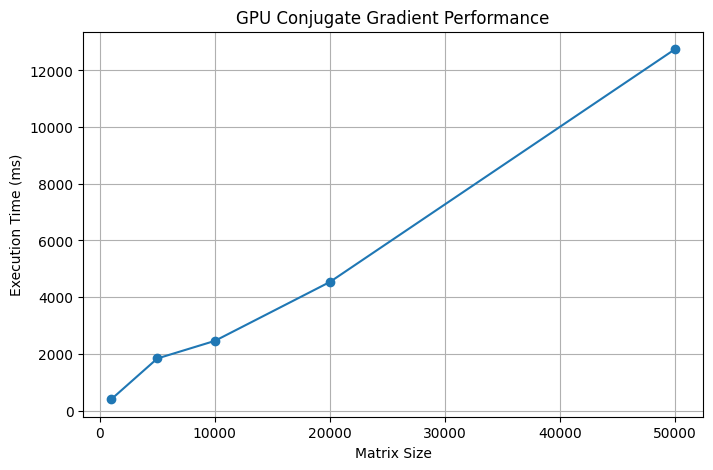

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    gpu_df["Matrix_Size"],
    gpu_df["Execution_Time_ms"],
    marker="o"
)

plt.xlabel("Matrix Size")
plt.ylabel("Execution Time (ms)")
plt.title("GPU Conjugate Gradient Performance")
plt.grid(True)

plt.show()

# ML Model for CG Algorithm

In [33]:
# Select input features
X = combined_df[
    ["Matrix_Size", "Hardware_Code"]
].copy()

# Prediction target
y = combined_df["Execution_Time_ms"].copy()

# Convert matrix size to logarithmic scale
X["Matrix_Size"] = np.log10(X["Matrix_Size"])

# Convert execution time to logarithmic scale
y = np.log10(y)

print("Input features:")
display(X)

print("\nTarget values:")
display(y)

print("\nDataset shape:", X.shape)

Input features:


,Matrix_Size,Hardware_Code
0,3.00000,0
1,3.69897,0
2,4.00000,0
3,4.30103,0
4,4.69897,0
5,3.00000,1
6,3.69897,1
7,4.00000,1
8,4.30103,1
9,4.69897,1



Target values:


,Execution_Time_ms
0,1.705232
1,2.522541
2,3.011490
3,3.877378
4,4.236709
5,2.600417
6,3.263986
7,3.390451
8,3.656657
9,4.105478



Dataset shape: (10, 2)


In [36]:
device = torch.device("cuda:0")

X_tensor = torch.tensor(
    X.values,
    dtype=torch.float32,
    device=device
)

y_tensor = torch.tensor(
    y.values,
    dtype=torch.float32,
    device=device
).reshape(-1, 1)

print("Input tensor shape:", X_tensor.shape)
print("Target tensor shape:", y_tensor.shape)

print("Input device:", X_tensor.device)
print("Target device:", y_tensor.device)

Input tensor shape: torch.Size([10, 2])
Target tensor shape: torch.Size([10, 1])
Input device: cuda:0
Target device: cuda:0


In [37]:
import torch.nn as nn

class CGPerformanceModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


model = CGPerformanceModel().to(device)

print(model)
print("\nModel device:", next(model.parameters()).device)

CGPerformanceModel(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)

Model device: cuda:0


In [38]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [39]:
print("Model parameter device:",
      next(model.parameters()).device)

print("Input device:", X_tensor.device)
print("Target device:", y_tensor.device)

assert next(model.parameters()).is_cuda
assert X_tensor.is_cuda
assert y_tensor.is_cuda

print("\nAll model components are on the GPU!")

Model parameter device: cuda:0
Input device: cuda:0
Target device: cuda:0

All model components are on the GPU!


In [40]:
epochs = 1000
loss_history = []

model.train()

for epoch in range(epochs):

    predictions = model(X_tensor)

    loss = criterion(predictions, y_tensor)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {loss.item():.6f}"
        )

print("\nTraining completed!")

Epoch [100/1000], Loss: 1.952441
Epoch [200/1000], Loss: 0.144137
Epoch [300/1000], Loss: 0.135881
Epoch [400/1000], Loss: 0.129070
Epoch [500/1000], Loss: 0.123475
Epoch [600/1000], Loss: 0.118769
Epoch [700/1000], Loss: 0.114579
Epoch [800/1000], Loss: 0.110575
Epoch [900/1000], Loss: 0.106522
Epoch [1000/1000], Loss: 0.102238

Training completed!


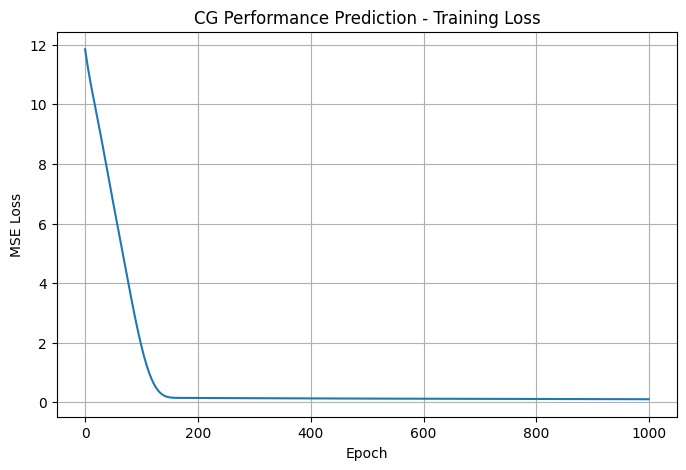

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("CG Performance Prediction - Training Loss")
plt.grid(True)
plt.show()

In [42]:
model.eval()

with torch.no_grad():
    predictions_log = model(X_tensor)

predictions_ms = torch.pow(10, predictions_log).cpu().numpy().flatten()
actual_ms = np.power(10, y_tensor.cpu().numpy().flatten())

results_df = pd.DataFrame({
    "Hardware": combined_df["Hardware"],
    "Matrix_Size": combined_df["Matrix_Size"],
    "Actual_Time_ms": actual_ms,
    "Predicted_Time_ms": predictions_ms
})

display(results_df)

,Hardware,Matrix_Size,Actual_Time_ms,Predicted_Time_ms
0,CPU,1000,50.726135,207.589981
1,CPU,5000,333.074249,801.024414
2,CPU,10000,1026.809448,1432.885986
3,CPU,20000,7540.119629,2563.167480
4,CPU,50000,17246.822266,5529.046875
5,Tesla T4,1000,398.489960,434.521454
6,Tesla T4,5000,1836.480591,1676.682495
7,Tesla T4,10000,2457.257812,2999.276123
8,Tesla T4,20000,4535.832031,5365.149414
9,Tesla T4,50000,12749.063477,11573.256836


In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(actual_ms, predictions_ms)

rmse = np.sqrt(
    mean_squared_error(actual_ms, predictions_ms)
)

r2 = r2_score(actual_ms, predictions_ms)

print("Model Evaluation")
print("-------------------------")
print(f"MAE:  {mae:.4f} ms")
print(f"RMSE: {rmse:.4f} ms")
print(f"R2:   {r2:.4f}")

Model Evaluation
-------------------------
MAE:  2046.8588 ms
RMSE: 4060.4886 ms
R2:   0.4784


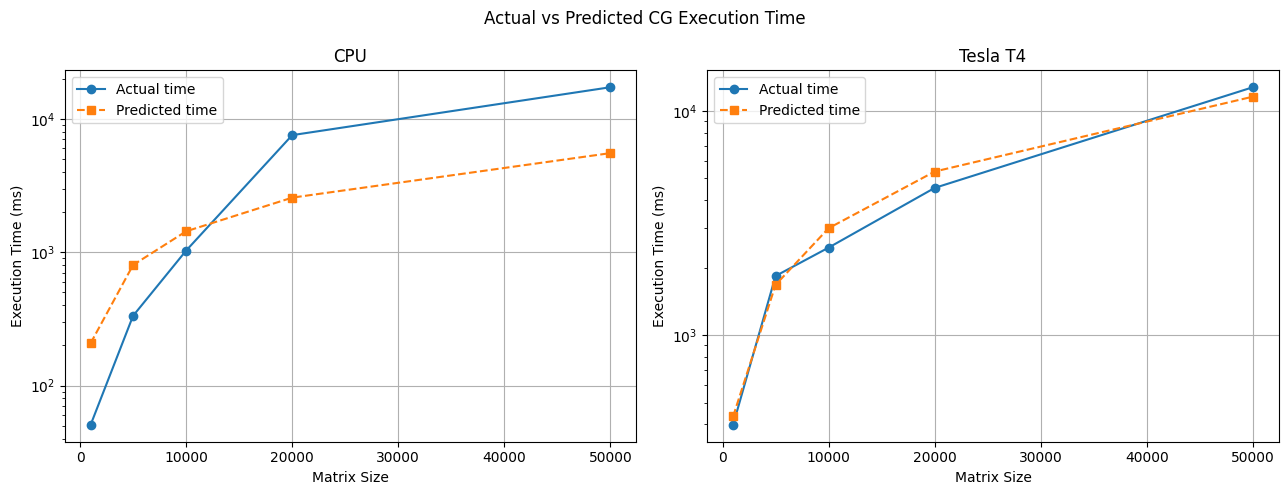

In [45]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, hardware in zip(axes, ["CPU", "Tesla T4"]):

    subset = results_df[
        results_df["Hardware"] == hardware
    ]

    ax.plot(
        subset["Matrix_Size"],
        subset["Actual_Time_ms"],
        marker="o",
        label="Actual time"
    )

    ax.plot(
        subset["Matrix_Size"],
        subset["Predicted_Time_ms"],
        marker="s",
        linestyle="--",
        label="Predicted time"
    )

    ax.set_yscale("log")
    ax.set_xlabel("Matrix Size")
    ax.set_ylabel("Execution Time (ms)")
    ax.set_title(hardware)
    ax.legend()
    ax.grid(True)

plt.suptitle("Actual vs Predicted CG Execution Time")
plt.tight_layout()
plt.show()

In [46]:
def predict_cg_performance(matrix_size, hardware):

    hardware_mapping = {
        "CPU": 0,
        "Tesla T4": 1
    }

    if hardware not in hardware_mapping:
        raise ValueError("Choose CPU or Tesla T4")

    if matrix_size <= 0:
        raise ValueError("Matrix size must be positive")

    model.eval()

    input_data = np.array([[
        np.log10(matrix_size),
        hardware_mapping[hardware]
    ]], dtype=np.float32)

    input_tensor = torch.tensor(
        input_data,
        dtype=torch.float32,
        device=device
    )

    with torch.no_grad():
        predicted_log_time = model(input_tensor)

    predicted_time = 10 ** predicted_log_time.item()

    return predicted_time

In [47]:
matrix_size = 10000
hardware = "Tesla T4"

predicted_time = predict_cg_performance(
    matrix_size,
    hardware
)

print("CG Performance Prediction")
print("----------------------------")
print("Matrix size:", matrix_size)
print("Hardware:", hardware)
print(f"Predicted execution time: {predicted_time:.3f} ms")
print(f"Predicted execution time: {predicted_time / 1000:.3f} seconds")

CG Performance Prediction
----------------------------
Matrix size: 10000
Hardware: Tesla T4
Predicted execution time: 2999.276 ms
Predicted execution time: 2.999 seconds


In [48]:
test_sizes = [1000, 5000, 10000, 20000, 50000]

prediction_results = []

for n in test_sizes:

    for hardware in ["CPU", "Tesla T4"]:

        predicted = predict_cg_performance(n, hardware)

        prediction_results.append({
            "Matrix_Size": n,
            "Hardware": hardware,
            "Predicted_Time_ms": predicted
        })

prediction_df = pd.DataFrame(prediction_results)

display(prediction_df)

,Matrix_Size,Hardware,Predicted_Time_ms
0,1000,CPU,207.589978
1,1000,Tesla T4,434.521447
2,5000,CPU,801.024416
3,5000,Tesla T4,1676.682481
4,10000,CPU,1432.885918
5,10000,Tesla T4,2999.276115
6,20000,CPU,2563.167564
7,20000,Tesla T4,5365.149559
8,50000,CPU,5529.046857
9,50000,Tesla T4,11573.256582


In [49]:
torch.save(
    model.state_dict(),
    "cg_performance_model.pth"
)

print("Model saved successfully!")

Model saved successfully!


In [50]:
actual = combined_df["Execution_Time_ms"].values
predicted = predictions_ms

error_df = pd.DataFrame({
    "Hardware": combined_df["Hardware"].values,
    "Matrix_Size": combined_df["Matrix_Size"].values,
    "Actual_ms": actual,
    "Predicted_ms": predicted
})

error_df["Absolute_Error_ms"] = abs(
    error_df["Actual_ms"] - error_df["Predicted_ms"]
)

error_df["Percentage_Error"] = (
    error_df["Absolute_Error_ms"] /
    error_df["Actual_ms"]
) * 100

display(error_df)

,Hardware,Matrix_Size,Actual_ms,Predicted_ms,Absolute_Error_ms,Percentage_Error
0,CPU,1000,50.726135,207.589981,156.863846,309.236740
1,CPU,5000,333.074298,801.024414,467.950116,140.494214
2,CPU,10000,1026.809271,1432.885986,406.076715,39.547434
3,CPU,20000,7540.120597,2563.167480,4976.953117,66.006280
4,CPU,50000,17246.822045,5529.046875,11717.775170,67.941648
5,Tesla T4,1000,398.489962,434.521454,36.031492,9.042007
6,Tesla T4,5000,1836.480547,1676.682495,159.798052,8.701320
7,Tesla T4,10000,2457.258039,2999.276123,542.018084,22.057842
8,Tesla T4,20000,4535.832459,5365.149414,829.316955,18.283677
9,Tesla T4,50000,12749.056963,11573.256836,1175.800127,9.222644


In [51]:
print("Mean Absolute Error:",
      error_df["Absolute_Error_ms"].mean(), "ms")

print("Mean Percentage Error:",
      error_df["Percentage_Error"].mean(), "%")

Mean Absolute Error: 2046.8583673913097 ms
Mean Percentage Error: 69.05338054124904 %


In [52]:
from sklearn.metrics import mean_absolute_error

for hardware in ["CPU", "Tesla T4"]:

    subset = error_df[
        error_df["Hardware"] == hardware
    ]

    mae = mean_absolute_error(
        subset["Actual_ms"],
        subset["Predicted_ms"]
    )

    mape = subset["Percentage_Error"].mean()

    print(f"\nHardware: {hardware}")
    print("-------------------------")
    print(f"MAE: {mae:.3f} ms")
    print(f"MAPE: {mape:.2f}%")


Hardware: CPU
-------------------------
MAE: 3545.124 ms
MAPE: 124.65%

Hardware: Tesla T4
-------------------------
MAE: 548.593 ms
MAPE: 13.46%


In [53]:
cpu_data = combined_df[
    combined_df["Hardware"] == "CPU"
].copy()

gpu_data = combined_df[
    combined_df["Hardware"] == "Tesla T4"
].copy()

def prepare_hardware_data(data):

    X = np.log10(
        data[["Matrix_Size"]].values
    ).astype(np.float32)

    y = np.log10(
        data["Execution_Time_ms"].values
    ).reshape(-1, 1).astype(np.float32)

    X = torch.tensor(X, dtype=torch.float32, device=device)
    y = torch.tensor(y, dtype=torch.float32, device=device)

    return X, y

X_cpu, y_cpu = prepare_hardware_data(cpu_data)
X_gpu, y_gpu = prepare_hardware_data(gpu_data)

print("CPU dataset:", X_cpu.shape, y_cpu.shape)
print("GPU dataset:", X_gpu.shape, y_gpu.shape)

CPU dataset: torch.Size([5, 1]) torch.Size([5, 1])
GPU dataset: torch.Size([5, 1]) torch.Size([5, 1])


In [54]:
class HardwareRegressionModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1, 8),
            nn.ReLU(),
            nn.Linear(8, 4),
            nn.ReLU(),
            nn.Linear(4, 1)
        )

    def forward(self, x):
        return self.network(x)

In [55]:
def train_hardware_model(X, y, epochs=1000):

    model = HardwareRegressionModel().to(device)

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    loss_history = []

    model.train()

    for epoch in range(epochs):

        predictions = model(X)

        loss = criterion(predictions, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())

    return model, loss_history

In [56]:
cpu_model, cpu_loss = train_hardware_model(
    X_cpu,
    y_cpu
)

print("CPU model training completed!")
print("Final training loss:", cpu_loss[-1])
print("Model device:", next(cpu_model.parameters()).device)

CPU model training completed!
Final training loss: 0.2522718906402588
Model device: cuda:0


In [57]:
gpu_model, gpu_loss = train_hardware_model(
    X_gpu,
    y_gpu
)

print("Tesla T4 model training completed!")
print("Final training loss:", gpu_loss[-1])
print("Model device:", next(gpu_model.parameters()).device)

Tesla T4 model training completed!
Final training loss: 0.014227129518985748
Model device: cuda:0


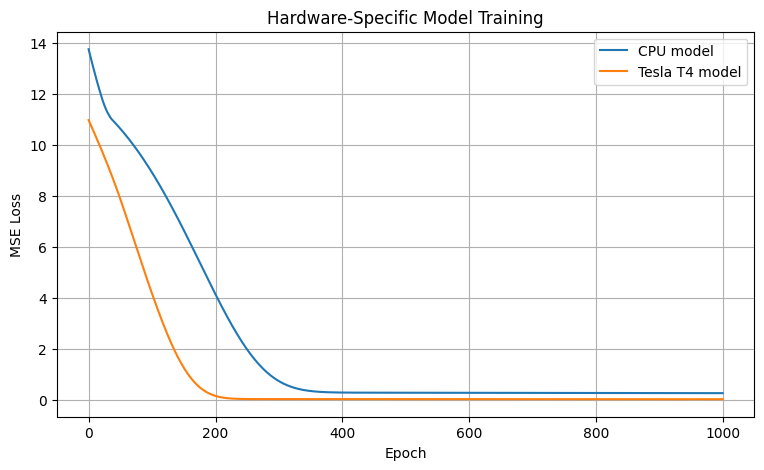

In [58]:
plt.figure(figsize=(9, 5))

plt.plot(cpu_loss, label="CPU model")
plt.plot(gpu_loss, label="Tesla T4 model")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Hardware-Specific Model Training")
plt.legend()
plt.grid(True)
plt.show()

In [59]:
def predict_separate_model(model, matrix_size):

    model.eval()

    x = torch.tensor(
        [[np.log10(matrix_size)]],
        dtype=torch.float32,
        device=device
    )

    with torch.no_grad():
        prediction = model(x).item()

    return 10 ** prediction

In [60]:
separate_results = []

for _, row in combined_df.iterrows():

    hardware = row["Hardware"]
    n = row["Matrix_Size"]

    selected_model = (
        cpu_model if hardware == "CPU" else gpu_model
    )

    predicted = predict_separate_model(selected_model, n)

    separate_results.append({
        "Hardware": hardware,
        "Matrix_Size": n,
        "Actual_ms": row["Execution_Time_ms"],
        "Predicted_ms": predicted,
        "Percentage_Error": abs(
            row["Execution_Time_ms"] - predicted
        ) / row["Execution_Time_ms"] * 100
    })

separate_results_df = pd.DataFrame(separate_results)

display(separate_results_df)

,Hardware,Matrix_Size,Actual_ms,Predicted_ms,Percentage_Error
0,CPU,1000,50.726135,268.837354,429.977997
1,CPU,5000,333.074298,888.518700,166.762913
2,CPU,10000,1026.809271,1486.839530,44.801919
3,CPU,20000,7540.120597,2488.064448,67.002326
4,CPU,50000,17246.822045,4914.066837,71.507407
5,Tesla T4,1000,398.489962,608.192315,52.624250
6,Tesla T4,5000,1836.480547,1789.848204,2.539223
7,Tesla T4,10000,2457.258039,2849.096411,15.946163
8,Tesla T4,20000,4535.832459,4535.209731,0.013729
9,Tesla T4,50000,12749.056963,8384.596735,34.233593


In [61]:
for hardware in ["CPU", "Tesla T4"]:

    subset = separate_results_df[
        separate_results_df["Hardware"] == hardware
    ]

    mae = np.mean(
        abs(subset["Actual_ms"] - subset["Predicted_ms"])
    )

    mape = subset["Percentage_Error"].mean()

    print(f"\n{hardware}")
    print("MAE:", round(mae, 3), "ms")
    print("MAPE:", round(mape, 2), "%")


CPU
MAE: 3723.679 ms
MAPE: 156.01 %

Tesla T4
MAE: 1002.651 ms
MAPE: 21.07 %


## ML Application of the workload

In [62]:
import ipywidgets as widgets
from IPython.display import display, clear_output

matrix_selector = widgets.Dropdown(
    options=[1000, 5000, 10000, 20000, 50000],
    value=10000,
    description="Matrix size:"
)

hardware_selector = widgets.Dropdown(
    options=["CPU", "Tesla T4"],
    value="Tesla T4",
    description="Hardware:"
)

predict_button = widgets.Button(
    description="Predict Performance",
    button_style="success"
)

output = widgets.Output()

def predict_button_clicked(button):

    with output:
        clear_output(wait=True)

        n = matrix_selector.value
        hardware = hardware_selector.value

        predicted_time = predict_cg_performance(
            n, hardware
        )

        print("CG PERFORMANCE PREDICTION")
        print("-----------------------------")
        print(f"Matrix size: {n} x {n}")
        print(f"Hardware: {hardware}")
        print(f"Predicted time: {predicted_time:.3f} ms")
        print(f"Predicted time: {predicted_time/1000:.3f} seconds")

predict_button.on_click(predict_button_clicked)

display(
    widgets.VBox([
        widgets.HTML("<h3>CG Performance Prediction System</h3>"),
        matrix_selector,
        hardware_selector,
        predict_button,
        output
    ])
)

In [63]:
def compare_hardware_predictions(n):

    cpu_time = predict_cg_performance(n, "CPU")
    gpu_time = predict_cg_performance(n, "Tesla T4")

    print(f"Matrix size: {n} x {n}")
    print("-" * 40)
    print(f"Predicted CPU time: {cpu_time:.3f} ms")
    print(f"Predicted T4 time: {gpu_time:.3f} ms")

    if cpu_time < gpu_time:
        print("\nPrediction: CPU is faster.")
    else:
        print("\nPrediction: Tesla T4 is faster.")

compare_hardware_predictions(50000)

Matrix size: 50000 x 50000
----------------------------------------
Predicted CPU time: 5529.047 ms
Predicted T4 time: 11573.257 ms

Prediction: CPU is faster.


In [64]:
import torch

torch.save(
    model.state_dict(),
    "cg_performance_model.pth"
)

print("Combined model saved!")

Combined model saved!


In [65]:
combined_df.to_csv(
    "week06_combined_cg_results.csv",
    index=False
)

results_df.to_csv(
    "week06_model_predictions.csv",
    index=False
)

separate_results_df.to_csv(
    "week06_hardware_specific_predictions.csv",
    index=False
)

print("All datasets saved!")

All datasets saved!


In [66]:
import zipfile

files_to_package = [
    "cg_performance_model.pth",
    "week06_combined_cg_results.csv",
    "week06_model_predictions.csv",
    "week06_hardware_specific_predictions.csv"
]

with zipfile.ZipFile(
    "week06_project_artifacts.zip",
    "w"
) as zip_file:

    for filename in files_to_package:
        zip_file.write(filename)

print("Week 6 artifacts packaged successfully!")

Week 6 artifacts packaged successfully!
